# 第 16 步：同池、同费率基准与成本路径对照

<!-- SNAPSHOT_NOTE -->

## 数据准备说明

本页记录完整快照上的实际运行。通过 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标：建立可比的基准与成本场景

第 15 步得到三因子策略累计亏损约 3.56%。单独看这个数字，仍无法判断相同股票池整体经历了什么，也不知道结果对交易费用有多敏感。本步建立同池等权基准，让基准、策略都分别运行 0、1、2 倍费率，共六条连续账户路径。

人工数据、2020—2025 年区间、综合评分、交易日历、执行时点和状态约束保持不变。变化只有组合选择范围和费用档位：基准选择同一个完整因子池的全部股票，策略选择其中综合分数前十名。比较选股表现时，策略与基准必须配对相同费率，不能混用零成本策略和一倍成本基准。

## 前置文件与运行命令

在仓库根目录执行：

```powershell
.\.venv\Scripts\python.exe examples/16_benchmark_cost_comparison.py
```

依赖安装沿用 `requirements-tested.txt` 和 `.[plots]`。脚本读取 [固定模拟快照](../../runs/first_demo_20261107/input/metadata.json)与[同一配置](../../configs/baseline.json)，重新计算相同因子，再分别运行六条路径。结果保存在 `runs/first_demo_20261107/lesson16_benchmark_cost/`。更改规则后的实验应另存，保留原始对照及其结果。

主要核对文件包括 [metrics.csv](../../runs/first_demo_20261107/lesson16_benchmark_cost/metrics.csv)、[relative_comparison.csv](../../runs/first_demo_20261107/lesson16_benchmark_cost/relative_comparison.csv)、[cost_impact.csv](../../runs/first_demo_20261107/lesson16_benchmark_cost/cost_impact.csv)、[fee_schedule.csv](../../runs/first_demo_20261107/lesson16_benchmark_cost/fee_schedule.csv)和[逐日比较路径](../../runs/first_demo_20261107/lesson16_benchmark_cost/comparison_paths.csv)。每个 `strategy_costX`、`benchmark_costX` 子目录同时保留 `daily/trades/orders/positions`，便于从对照表回到逐笔账。

![同池基准与成本敏感性图](../../runs/first_demo_20261107/lesson16_benchmark_cost/benchmark_cost_comparison.png)

图中依次展示一倍费率的策略与基准、三档策略净值，以及策略相对于同档基准的财富比值。0 倍只是关闭费用，并没有解除已提供的买卖状态约束；它仍不是一个保证无摩擦、无限容量的现实账户。

## “同池等权基准”的定义

本步基准不是沪深 300，也不代表所有 A 股。每个信号日先要求三项因子与综合分数完整，再从这个截面定义共同候选池。基准给池内全部股票相同的目标市值权重，策略只取前十名。当前模拟快照在 71 个信号日均有 40 只基准目标、10 只策略目标，名单保存为 [signal_pools.csv](../../runs/first_demo_20261107/lesson16_benchmark_cost/signal_pools.csv)。

核心接口保持简单：

```python
for portfolio, score in [("benchmark", None), ("strategy", "composite")]:
    result = run_backtest(prices, factors, calendar, scenario, score_column=score)
```

第一行明确两个组合的差别；`None` 表示不按分数截取前十名，仍使用同一完整综合分数池。第二行让两个组合共享同一引擎、同一费率档位与同一日历。基准在月末收盘形成目标，下一交易日开盘执行；成交后仍可能因费用、限制和价格变化而偏离等权。

这个基准不能描述为“每天维持精确等权”，因为那需要额外的日频再平衡；也不能描述为“开始时买入后永久不动”，因为它确实每月按目标调整。成交笔数较多也不必然代表成本更高：基准经常只是小额权重修正，本项目费用按成交金额计收，且没有最低佣金模型。

## 六组实验与费率设置

使用倍率 (m\in\{0,1,2\})，同时缩放三项教学参数：

| 费用倍率 | 单边佣金 | 滑点 | 卖出税 |
| --- | ---: | ---: | ---: |
| 0 倍 | 0 bps | 0 bps | 0 bps |
| 1 倍 | 3 bps | 5 bps | 5 bps |
| 2 倍 | 6 bps | 10 bps | 10 bps |

```python
scenario = dict(config, cost_multiplier=multiplier)
result = run_backtest(prices, factors, calendar, scenario, score_column=score)
```

第一行创建该档位的配置副本，避免在全局配置上不断累乘费率；第二行从同样的初始 100 万元重新模拟账户。不同档位是完整的反事实路径，不是从一条无费曲线尾部直接扣掉一笔成本。每条路径都有自己的现金、目标数量、成交数量及其后复利。

## 收益差与相对财富收益

设策略和基准以同样的起点 1 开始，期末净值分别为 (W_s,W_b)。两种比较回答不同的问题：

$$
\text{累计收益差}=R_s-R_b=W_s-W_b,
$$

$$
\text{比值相对收益}=W_s/W_b-1.
$$

前者乘 100 后以“百分点”展示，比较的是相对于初始资金的收益率差；后者以基准期末财富为分母，回答策略期末财富比基准多或少多少比例。两个数字不会普遍相等。

逐日相对财富也采用一致的定义：

```python
relative_nav = strategy["nav"] / benchmark["nav"]
relative_daily_return = (1 + strategy["return"]) / (1 + benchmark["return"]) - 1
```

第一行直接比较财富比值，第二行计算该比值路径的日变化，再核对它的增长倍数连乘能还原第一行。“每日收益相减”的连乘不能代替相对财富。这个比值也不代表已经执行过的多空策略，它没有包括真实做空、融资和再平衡所需的完整交易条件。

## 六组模拟结果

以下四项指标沿用第 15 步定义，回撤显示正幅度。每条路径都包含 1566 个账户日收益。

| 组合 | 累计收益 | 252 日年化 | 年化波动 | 最大回撤 | 期末权益 | 累计成本 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 基准 0 倍 | 14.7084% | 2.2327% | 12.7306% | 20.6979% | 1147083.8777 | 0 |
| 策略 0 倍 | 6.5523% | 1.0265% | 13.5830% | 24.6040% | 1065523.4789 | 0 |
| 基准 1 倍 | 14.1581% | 2.1537% | 12.7301% | 20.7582% | 1141581.2475 | 5350.0901 |
| 策略 1 倍 | -3.5632% | -0.5822% | 13.6014% | 29.7750% | 964367.9914 | 93205.4195 |
| 基准 2 倍 | 13.6113% | 2.0748% | 12.7298% | 20.8184% | 1136112.5434 | 10666.3905 |
| 策略 2 倍 | -12.7163% | -2.1648% | 13.6359% | 34.5894% | 872836.7528 | 177673.6262 |

同档配对结果如下：

| 配对档位 | 策略累计收益减基准 | 策略期末净值除以基准减一 |
| --- | ---: | ---: |
| 0 倍 | -8.1560 个百分点 | -7.1102% |
| 1 倍 | -17.7213 个百分点 | -15.5235% |
| 2 倍 | -26.3276 个百分点 | -23.1734% |

0 倍比较尤其值得保留：即使关闭费用，策略也落后于同档无费基准。因此，不能把本模拟样本中的全部落后归因于手续费。固定随机样本并不能给出真实市场的普遍结论，它在这里用于练习有纪律的对照方法。

## 终值差为什么不等于“已付费用”

无费策略终值为 `1065523.478859271`，一倍成本终值为 `964367.9913810544`，相差 `101155.48747821653` 元。但一倍路径累计记录的佣金、卖出税与滑点只有 `93205.4194780295` 元，两者还差 `7950.068000187035` 元。

这段差异来自费用对可投资现金、单位数、后续成交规模与复利路径的影响。它不是额外收走的一笔手续费，也不能仅凭它判断数据出错。代码将两种量分别记录：

```python
wealth_gap = zero_fee_equity - cases.loc[multiplier, "final_equity"]
recorded_cost = cases.loc[multiplier, "total_cost"]
```

终值差、账面成本及其差额分别保存，简单相减并不等于完成严格的全部经济归因。类似地，2 倍费率的实付成本约为 1 倍的 1.9063 倍，而不是必然恰好两倍，因为账户资产和交易金额已经不同。

## 字段检查、误区与验收

`metrics.csv` 使用 `portfolio`、`cost_multiplier`、`case` 唯一识别路径，不能凭行顺序猜档位。`max_drawdown` 为正幅度，`max_drawdown_signed` 保留负值；`return_gap_percentage_points` 已经乘 100，不能再次当作小数百分率转换。`total_cost` 只是记录汇总，不再扣减净值。

验收包括：六条日期序列相同，首日都为 100 万元与净值 1；费用表与倍率匹配；基准和策略候选池一致；买入代码属于相应信号目标；一倍策略与第 15 步账户一致；每日权益、收益连乘与费用汇总均能复核。-17.7213 个百分点与 -15.5235% 的区别，也应能从公式解释清楚。

本步完成同一规则在六个明确场景下的对照。下一步直接从一倍成本的连续日收益中切出开发、验证和测试年份，不重新注资或回测，观察表现是否集中在某一段。

## 补充核对：成交金额、换手与档位可比性

基准一倍路径有 2794 笔成交，策略一倍有 1164 笔，但基准总成本远低于策略。这与按金额收费一致：基准经常调整很小的权重偏差，策略则反复卖出退出前十的股票并买入新股票。单凭交易次数推断成本，会忽略每笔规模。`annual_turnover` 使用买入加卖出成交金额除以调仓前开盘权益的日比率，再按 252 日年化，没有再除以二；与其他资料比较时，需先核对单边或双边口径。

实际持仓数量不强行修正成目标数量。人工状态中存在买入受阻或卖出受阻，费用档位改变现金与数量，但不改变当时已经保存的评分规则。0 倍路径仍使用同一套状态和候选池，才能把这组实验称为费用敏感性；如果同时删去状态约束、换股票池或改变调仓频率，结果就混入其他变化，无法只围绕成本解释。

[完整脚本](../../examples/16_benchmark_cost_comparison.py) · [下一步：事后分段稳定性](../17_split_stability/README.md)

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/16_benchmark_cost_comparison.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
r"""第十六课：同池等权基准、相对收益与 0/1/2 倍教学成本。

运行：.\.venv\Scripts\python.exe examples/16_benchmark_cost_comparison.py
六条路径均使用同一人工数据、因子完整股票池、起止日期和成交规则。
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from ashare_lab.backtest import metrics, run_backtest
from ashare_lab.config import load_config
from ashare_lab.data import load_dataset, write_json
from ashare_lab.factors import compute_factors, monthly_signal_dates

### 完整实现 · 单元 2

In [3]:
def build_signal_pools(factors, calendar, config):
    """记录每个信号日的目标池；执行日状态只影响成交，不影响排名。"""
    rows = []
    targets = {"benchmark": {}, "strategy": {}}
    for signal_date in monthly_signal_dates(calendar):
        execution_date = calendar[calendar.get_loc(signal_date) + 1]
        if not (pd.Timestamp(config["start"]) <= signal_date < execution_date <= pd.Timestamp(config["end"])):
            continue
        cross = factors.loc[factors["date"].eq(signal_date)]
        cross = cross.loc[np.isfinite(cross["composite"])]
        ranked = cross.sort_values(["composite", "symbol"], ascending=[False, True])
        whole_pool = ranked["symbol"].tolist()
        top_names = ranked.head(config["top_n"])["symbol"].tolist()
        if not whole_pool:
            raise ValueError("本课信号日的完整因子股票池为空。")
        targets["benchmark"][signal_date] = set(whole_pool)
        targets["strategy"][signal_date] = set(top_names)
        rows.append(dict(signal_date=signal_date, execution_date=execution_date,
                         benchmark_target_count=len(whole_pool), strategy_target_count=len(top_names),
                         benchmark_symbols="|".join(sorted(whole_pool)), strategy_symbols="|".join(top_names)))
    return pd.DataFrame(rows), targets

### 完整实现 · 单元 3

In [4]:
def audit_and_save(result, folder, target_sets):
    """核对现金/持仓/费用及买入名单，保存可逐笔检查的表。"""
    daily = result.daily
    invested = result.positions.groupby("date")["market_value"].sum()
    values = daily["date"].map(invested).fillna(0)  # 没有持仓的日期市值为 0，不填补行情。
    np.testing.assert_allclose(daily["equity"], daily["cash"] + values, rtol=0, atol=1e-7)
    np.testing.assert_allclose(daily["nav"], daily["equity"] / daily["equity"].iloc[0],
                               rtol=0, atol=1e-10)  # 本课首日是净值 1 的持币日。
    assert (daily["cash"] >= 0).all()
    assert (result.trades["date"] > result.trades["signal_date"]).all()
    recorded_cost = result.trades[["commission", "tax", "slippage_cost"]].sum().sum()
    np.testing.assert_allclose(daily["cost"].sum(), recorded_cost, rtol=0, atol=1e-7)
    for signal_date, buys in result.trades.loc[result.trades["side"].eq("buy")].groupby("signal_date"):
        assert set(buys["symbol"]).issubset(target_sets[signal_date])
    folder.mkdir(parents=True, exist_ok=True)
    for name in ["daily", "trades", "orders", "positions"]:
        getattr(result, name).to_csv(folder / f"{name}.csv", index=False, date_format="%Y-%m-%d")

### 完整实现 · 单元 4

In [5]:
def build_comparison(results):
    """同费率配对：收益差用小数存储，显示时转换为百分点。"""
    dates = results["strategy_cost1"].daily["date"].reset_index(drop=True)
    paths = pd.DataFrame({"date": dates})
    for name, result in results.items():
        pd.testing.assert_series_equal(result.daily["date"].reset_index(drop=True), dates)
        paths[f"{name}_nav"] = result.daily["nav"].to_numpy()

    rows = []
    for multiplier in [0, 1, 2]:
        strategy = results[f"strategy_cost{multiplier}"].daily
        benchmark = results[f"benchmark_cost{multiplier}"].daily

        # 相对财富曲线是两条同起点净值之比，不是收益率之差的连乘。
        relative_nav = strategy["nav"] / benchmark["nav"]
        relative_daily_return = (1 + strategy["return"]) / (1 + benchmark["return"]) - 1
        np.testing.assert_allclose((1 + relative_daily_return).cumprod(skipna=False), relative_nav,
                                   rtol=0, atol=1e-10)
        paths[f"relative_nav_cost{multiplier}"] = relative_nav
        paths[f"relative_return_cost{multiplier}"] = relative_nav - 1
        paths[f"cumulative_return_gap_cost{multiplier}"] = strategy["nav"] - benchmark["nav"]

        strategy_return = strategy["nav"].iloc[-1] - 1
        benchmark_return = benchmark["nav"].iloc[-1] - 1
        return_gap = strategy_return - benchmark_return
        relative_return = relative_nav.iloc[-1] - 1
        rows.append(dict(cost_multiplier=multiplier, strategy_total_return=float(strategy_return),
                         benchmark_total_return=float(benchmark_return), return_gap=float(return_gap),
                         return_gap_percentage_points=float(return_gap * 100), relative_return=float(relative_return)))
    return paths, pd.DataFrame(rows)

### 完整实现 · 单元 5

In [6]:
def build_cost_impact(summary):
    """终值差包含费用改变资金/持仓及复利路径的影响，不等于累计费用。"""
    rows = []
    for portfolio in ["strategy", "benchmark"]:
        cases = summary.loc[summary["portfolio"].eq(portfolio)].set_index("cost_multiplier")
        zero_fee_equity = cases.loc[0, "final_equity"]
        for multiplier in [1, 2]:
            wealth_gap = zero_fee_equity - cases.loc[multiplier, "final_equity"]
            recorded_cost = cases.loc[multiplier, "total_cost"]
            rows.append(dict(portfolio=portfolio, cost_multiplier=multiplier,
                             terminal_wealth_gap_vs_zero_cost=float(wealth_gap),
                             recorded_total_cost=float(recorded_cost),
                             gap_minus_recorded_cost=float(wealth_gap - recorded_cost)))
    return pd.DataFrame(rows)

### 完整实现 · 单元 6

In [7]:
def plot_comparison(paths, summary, output_path):
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.size"] = 11
    fig, axes = plt.subplots(3, 1, figsize=(11.5, 10.5), sharex=True, layout="constrained")
    fig.suptitle("基准比较与交易成本敏感性（模拟数据，2020—2025）", fontsize=17)
    dates = paths["date"]
    styles = {0: ("#977312", "--"), 1: ("#3268A8", "-"), 2: ("#B46A31", ":")}

    ax = axes[0]
    ax.set_title("1 倍教学费率：前 10 只策略与完整因子池等权基准", loc="left", fontsize=12, pad=10)
    ax.plot(dates, paths["strategy_cost1_nav"], color="#3268A8", linewidth=1.5,
            label=f"三因子策略（期末 {paths['strategy_cost1_nav'].iloc[-1]:.4f}）")
    ax.plot(dates, paths["benchmark_cost1_nav"], color="#747D86", linestyle="--", linewidth=1.4,
            label=f"同池等权基准（期末 {paths['benchmark_cost1_nav'].iloc[-1]:.4f}）")
    ax.axhline(1, color="#9FA6AD", linestyle=":", linewidth=0.8)
    ax.set_ylabel("净值（初始 = 1）")
    ax.legend(loc="upper left", frameon=False, fontsize=10)
    net_values = paths[["strategy_cost1_nav", "benchmark_cost1_nav"]]
    ax.set_ylim(net_values.min().min() - 0.06, net_values.max().max() + 0.12)

    ax = axes[1]
    ax.set_title("三因子策略：仅调整费用档位，分别重新回测", loc="left", fontsize=12, pad=10)
    for multiplier, (color, line) in styles.items():
        column = f"strategy_cost{multiplier}_nav"
        ax.plot(dates, paths[column], color=color, linestyle=line, linewidth=1.5,
                label=f"{multiplier} 倍成本（期末 {paths[column].iloc[-1]:.4f}）")
    ax.axhline(1, color="#9FA6AD", linestyle=":", linewidth=0.8)
    ax.set_ylabel("净值（初始 = 1）")
    cost_values = paths[[f"strategy_cost{m}_nav" for m in styles]]
    ax.set_ylim(cost_values.min().min() - 0.05, cost_values.max().max() + 0.16)
    ax.legend(loc="upper left", ncol=3, frameon=False, fontsize=10)

    ax = axes[2]
    ax.set_title("各档策略相对同档基准：净值比值 − 1", loc="left", fontsize=12, pad=10)
    for multiplier, (color, line) in styles.items():
        column = f"relative_return_cost{multiplier}"
        ax.plot(dates, paths[column], color=color, linestyle=line, linewidth=1.5,
                label=f"{multiplier} 倍配对（期末 {paths[column].iloc[-1]:.2%}）")
    ax.axhline(0, color="#747D86", linewidth=0.9)
    ax.set_ylabel("相对收益（比值口径）")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    relative_values = paths[[f"relative_return_cost{m}" for m in styles]]
    ax.set_ylim(relative_values.min().min() - 0.025, relative_values.max().max() + 0.09)
    ax.legend(loc="upper left", ncol=3, frameon=False, fontsize=10)

    ticks = pd.date_range(dates.iloc[0], dates.iloc[-1], freq="YS")
    ticks = ticks.union(pd.DatetimeIndex([dates.iloc[0], dates.iloc[-1]]))
    axes[-1].set_xticks(ticks)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    axes[-1].set_xlim(dates.iloc[0] - pd.Timedelta(days=20), dates.iloc[-1] + pd.Timedelta(days=20))
    axes[-1].set_xlabel("日期（人工行情与工作日日历；期末按收盘估值，仍有持仓）")
    for ax in axes:
        ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", labelsize=10)
    fig.savefig(output_path, dpi=180)
    plt.close(fig)

### 完整实现 · 单元 7

In [8]:
def main():
    project_dir = Path(__file__).resolve().parents[1]
    run_dir = project_dir / "runs" / "first_demo_20261107"
    output_dir = run_dir / "lesson16_benchmark_cost"
    prices, universe, calendar, _ = load_dataset(run_dir / "input")
    config = load_config(project_dir / "configs" / "baseline.json")
    config["calendar_dates"] = calendar.strftime("%Y-%m-%d").tolist()
    factors = compute_factors(prices, universe, config)
    signal_pools, targets = build_signal_pools(factors, calendar, config)

    # 同一费率同时比较策略和基准；每个档位重新模拟真实现金与实际持仓。
    results = {}
    metric_rows = []
    fee_rows = []
    for multiplier in [0, 1, 2]:
        scenario = dict(config, cost_multiplier=multiplier)
        fee_rows.append(dict(cost_multiplier=multiplier,
                             commission_bps=config["commission_bps"] * multiplier,
                             slippage_bps=config["slippage_bps"] * multiplier,
                             sell_tax_bps=config["sell_tax_bps"] * multiplier))
        for portfolio, score in [("benchmark", None), ("strategy", "composite")]:
            name = f"{portfolio}_cost{multiplier}"
            result = run_backtest(prices, factors, calendar, scenario, score_column=score)
            audit_and_save(result, output_dir / name, targets[portfolio])
            results[name] = result
            values = metrics(result.daily)
            signed_drawdown = values.pop("max_drawdown")
            metric_rows.append(dict(case=name, portfolio=portfolio, cost_multiplier=multiplier,
                                    n_days=len(result.daily), **values,
                                    max_drawdown=-signed_drawdown, max_drawdown_signed=signed_drawdown,
                                    final_equity=float(result.daily["equity"].iloc[-1]),
                                    final_nav=float(result.daily["nav"].iloc[-1]),
                                    commission=float(result.trades["commission"].sum()),
                                    sell_tax=float(result.trades["tax"].sum()),
                                    slippage=float(result.trades["slippage_cost"].sum())))
            print(f"完成 {name}: 累计收益 {values['total_return']:.6%}", flush=True)

    summary = pd.DataFrame(metric_rows)
    paths, comparison = build_comparison(results)
    cost_impact = build_cost_impact(summary)

    # 1 倍策略必须与上一课完整历史结果一致。
    previous_path = run_dir / "lesson15_full_backtest" / "daily.csv"
    if previous_path.exists():
        previous = pd.read_csv(previous_path, parse_dates=["date"])
        current = results["strategy_cost1"].daily
        pd.testing.assert_frame_equal(current, previous[current.columns], check_exact=False, rtol=0, atol=1e-8)

    summary.to_csv(output_dir / "metrics.csv", index=False)
    comparison.to_csv(output_dir / "relative_comparison.csv", index=False)
    cost_impact.to_csv(output_dir / "cost_impact.csv", index=False)
    paths.to_csv(output_dir / "comparison_paths.csv", index=False, date_format="%Y-%m-%d")
    signal_pools.to_csv(output_dir / "signal_pools.csv", index=False, date_format="%Y-%m-%d")
    pd.DataFrame(fee_rows).to_csv(output_dir / "fee_schedule.csv", index=False)
    write_json(output_dir / "config_snapshot.json", {k: v for k, v in config.items() if k != "calendar_dates"})
    write_json(output_dir / "methodology.json", dict(
        source="synthetic teaching data; weekday calendar, not an A-share exchange calendar",
        start=config["start"], end=config["end"], annual_sessions=252,
        benchmark="monthly target equal weight across the same finite-composite pool, score_column=None",
        strategy="top 10 by composite from that same pool, monthly target equal weight",
        execution="next-session open, sell first, cash-scaled buys, supplied status flags",
        fees="fixed teaching bps; multiplier scales commission, slippage and sell tax together",
        relative_return="strategy NAV / same-cost benchmark NAV - 1; not a tradable long-short return",
        return_gap="strategy total return - benchmark total return; multiply by 100 for percentage points",
        cost_comparison="separately rerun paths; terminal wealth gap includes costs and changed investment paths",
        terminal_valuation="last close; no hypothetical liquidation",
    ))
    plot_comparison(paths, summary, output_dir / "benchmark_cost_comparison.png")

    print("\n六组指标（收益和回撤以小数存储）：")
    print(summary[["case", "total_return", "annual_return", "annual_volatility", "max_drawdown", "total_cost"]].to_string(index=False))
    print("\n同费率配对比较：")
    print(comparison.to_string(index=False))
    print("\n终值差与累计成本：")
    print(cost_impact.to_string(index=False))
    print("\n本课结果目录：", output_dir)

### 完整实现 · 单元 8

In [9]:
if __name__ == "__main__":
    main()

完成 benchmark_cost0: 累计收益 14.708388%


完成 strategy_cost0: 累计收益 6.552348%


完成 benchmark_cost1: 累计收益 14.158125%


完成 strategy_cost1: 累计收益 -3.563201%


完成 benchmark_cost2: 累计收益 13.611254%


完成 strategy_cost2: 累计收益 -12.716325%



六组指标（收益和回撤以小数存储）：
           case  total_return  annual_return  annual_volatility  max_drawdown    total_cost
benchmark_cost0      0.147084       0.022327           0.127306      0.206979      0.000000
 strategy_cost0      0.065523       0.010265           0.135830      0.246040      0.000000
benchmark_cost1      0.141581       0.021537           0.127301      0.207582   5350.090081
 strategy_cost1     -0.035632      -0.005822           0.136014      0.297750  93205.419478
benchmark_cost2      0.136113       0.020748           0.127298      0.208184  10666.390527
 strategy_cost2     -0.127163      -0.021648           0.136359      0.345894 177673.626188

同费率配对比较：
 cost_multiplier  strategy_total_return  benchmark_total_return  return_gap  return_gap_percentage_points  relative_return
               0               0.065523                0.147084   -0.081560                     -8.156040        -0.071102
               1              -0.035632                0.141581   -0.177213      

## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

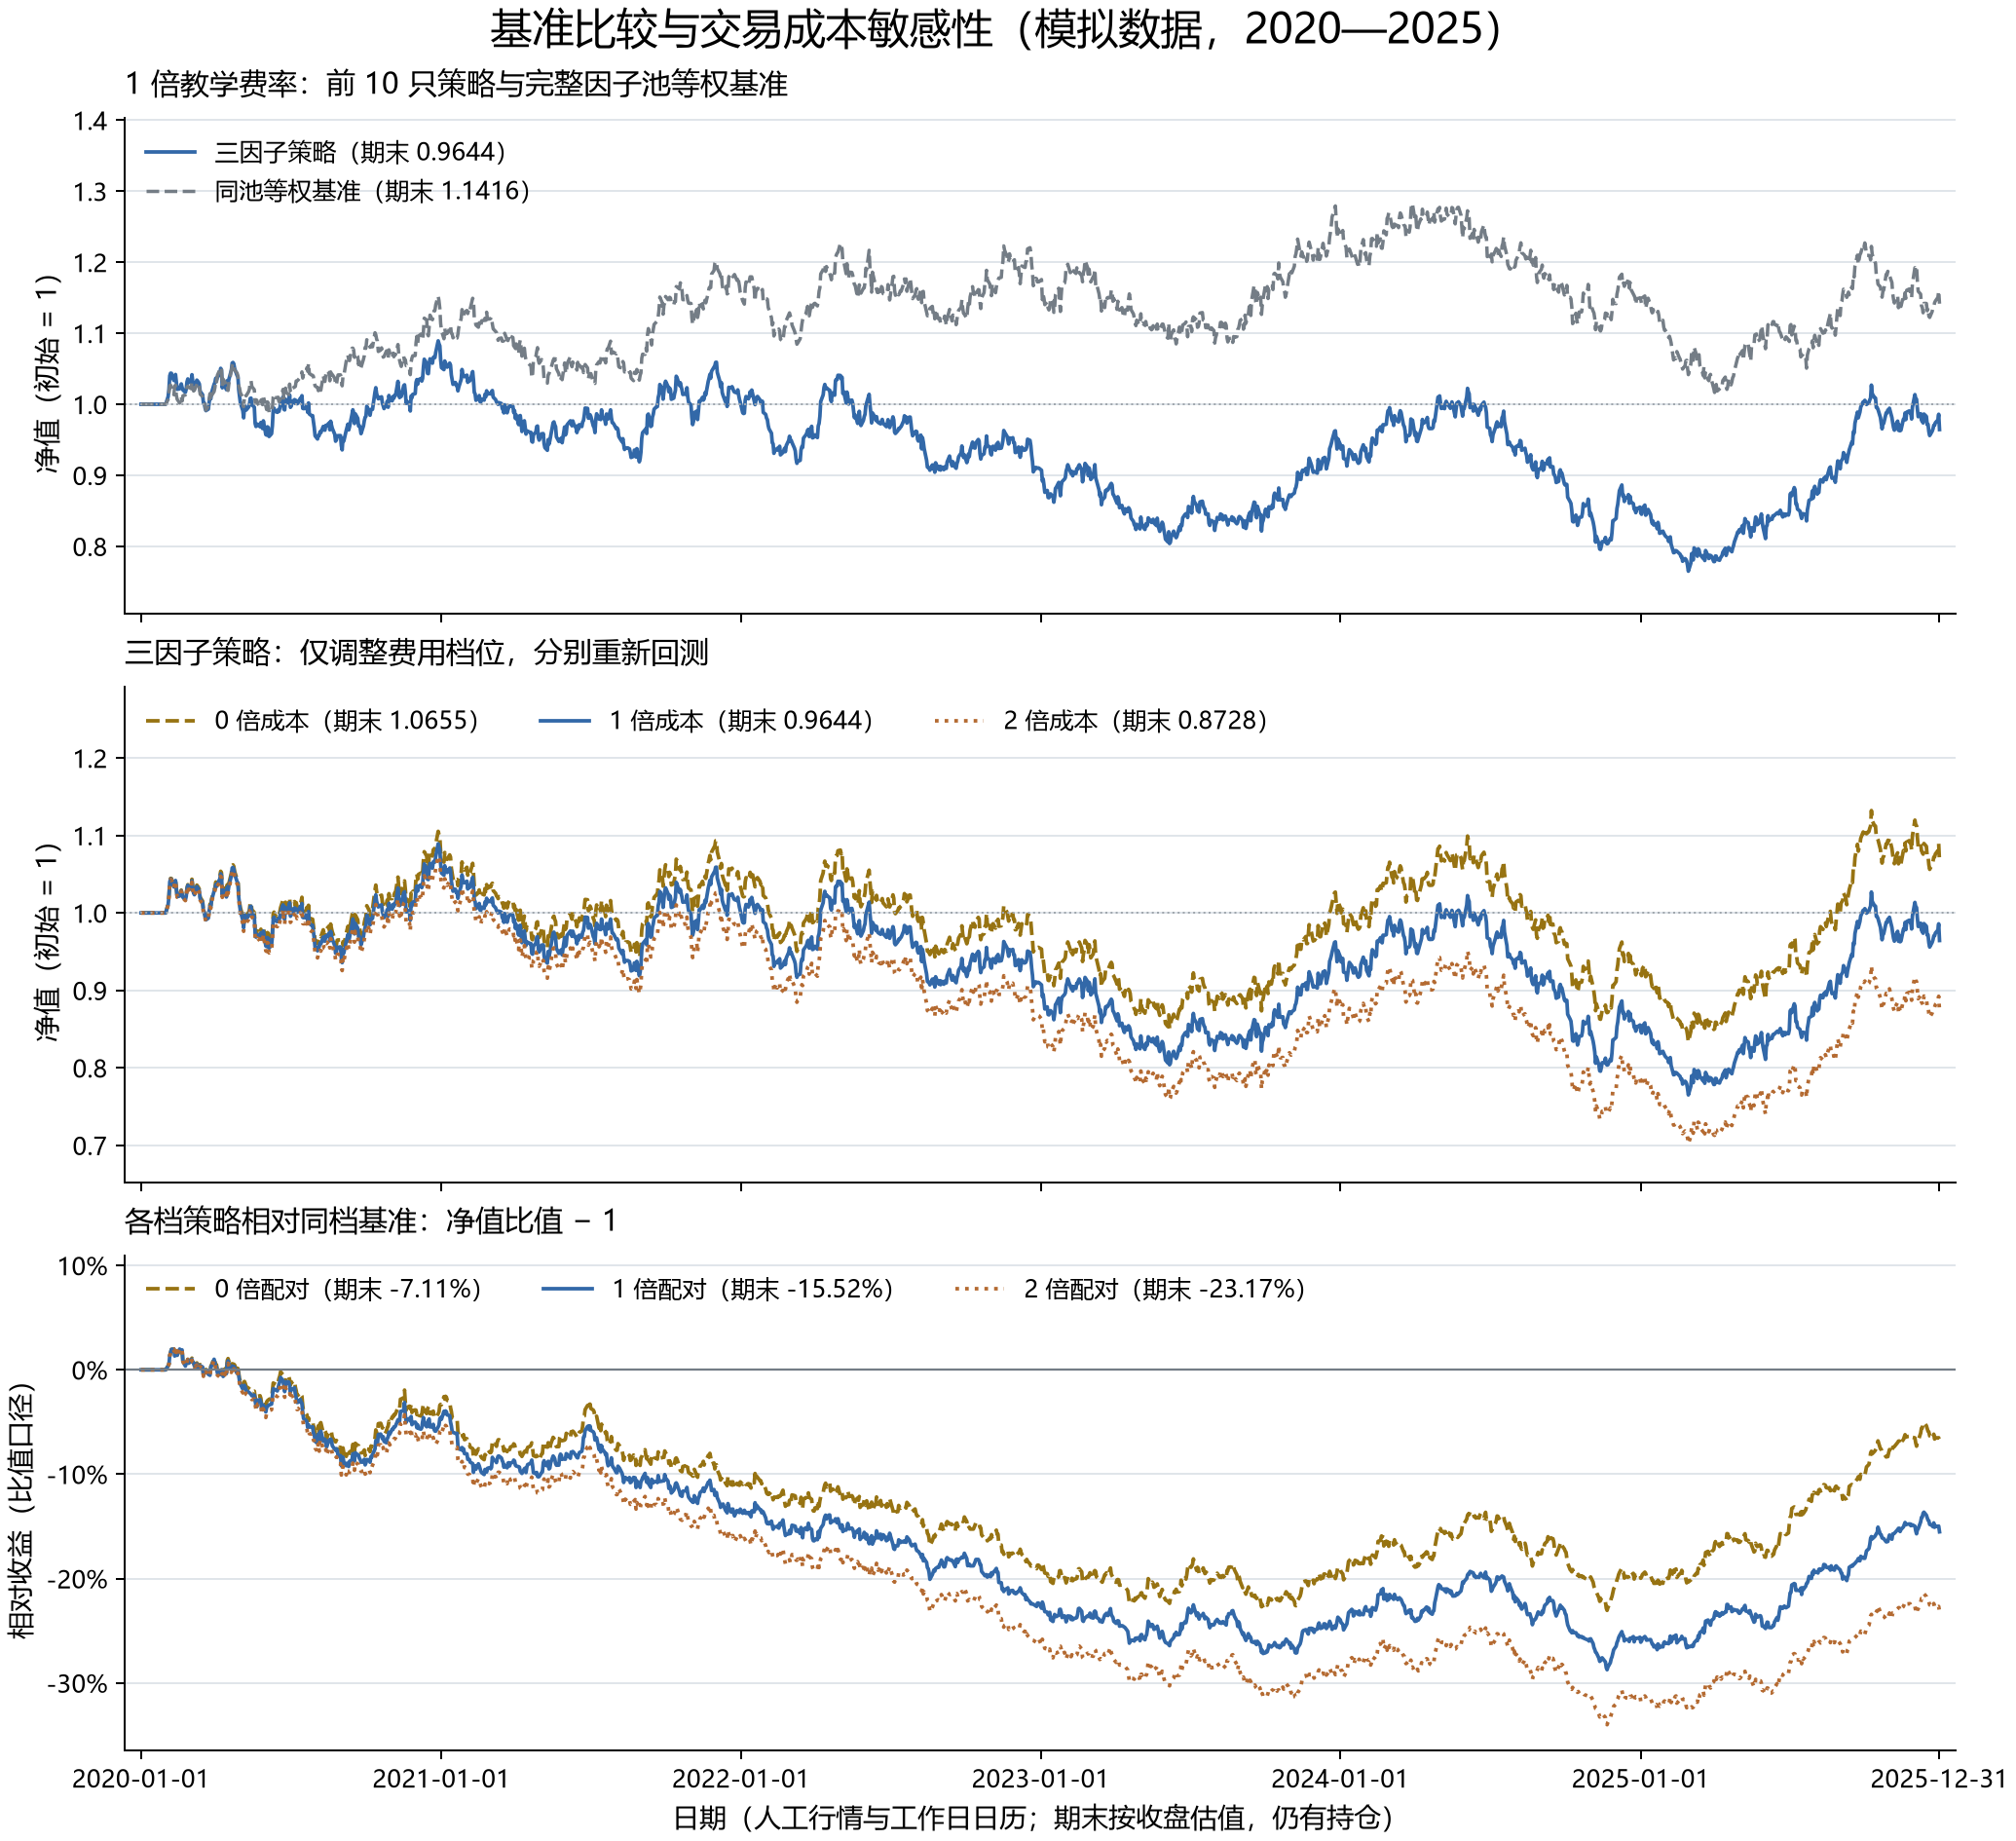

In [10]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/first_demo_20261107/lesson16_benchmark_cost/benchmark_cost_comparison.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。